In [2]:
import pandas as pd

## PANDAS

In [3]:
df = pd.read_csv('global_ecommerce_sales.csv')

In [4]:
df.head()
df.shape

(2000, 15)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2000 non-null   str    
 1   Order_Date        2000 non-null   str    
 2   Customer_Name     2000 non-null   str    
 3   Customer_Segment  2000 non-null   str    
 4   Country           2000 non-null   str    
 5   Region            2000 non-null   str    
 6   Product_Category  2000 non-null   str    
 7   Product_Name      2000 non-null   str    
 8   Quantity          2000 non-null   int64  
 9   Unit_Price        2000 non-null   float64
 10  Discount_Percent  2000 non-null   int64  
 11  Total_Sales       2000 non-null   float64
 12  Shipping_Cost     2000 non-null   float64
 13  Profit            2000 non-null   float64
 14  Payment_Method    2000 non-null   str    
dtypes: float64(4), int64(2), str(9)
memory usage: 234.5 KB


In [6]:
df.describe()

,Quantity,Unit_Price,Discount_Percent,Total_Sales,Shipping_Cost,Profit
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,3.557500,73.329490,8.572500,242.279670,12.90212,79.436160
std,2.704506,79.311014,7.261274,382.583802,5.22319,137.573593
min,1.000000,3.030000,0.000000,2.420000,5.52000,-11.280000
25%,2.000000,18.757500,0.000000,41.227500,9.45750,6.865000
50%,3.000000,46.420000,10.000000,113.125000,11.84500,32.830000
75%,5.000000,90.250000,15.000000,266.552500,14.92000,90.297500
max,15.000000,472.560000,30.000000,3813.980000,40.44000,1373.630000


In [7]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Customer_Name       0
Customer_Segment    0
Country             0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount_Percent    0
Total_Sales         0
Shipping_Cost       0
Profit              0
Payment_Method      0
dtype: int64

In [8]:
df.dtypes

Order_ID                str
Order_Date              str
Customer_Name           str
Customer_Segment        str
Country                 str
Region                  str
Product_Category        str
Product_Name            str
Quantity              int64
Unit_Price          float64
Discount_Percent      int64
Total_Sales         float64
Shipping_Cost       float64
Profit              float64
Payment_Method          str
dtype: object

In [9]:
df.duplicated().sum()   

np.int64(0)

In [10]:

df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [11]:
print("Earliest order:", df["Order_Date"].min())
print("Latest order:", df["Order_Date"].max())

Earliest order: 2023-01-02 00:00:00
Latest order: 2025-12-31 00:00:00


In [12]:
# basic
total_revenue = df["Total_Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique() #unique order_ID count
average_order_value = df["Total_Sales"].mean()
profit_margin = (total_profit / total_revenue) * 100

print(f"Total Revenue: ${total_revenue.round(2)}")
print(f"Total Profit: ${total_profit.round(2)}")
print("Total Orders:", total_orders)
print(f"Average Order Value:${average_order_value.round(2)}")
print(f"Overall Profit Margin:", profit_margin.round(2), "%")

Total Revenue: $484559.34
Total Profit: $158872.32
Total Orders: 2000
Average Order Value:$242.28
Overall Profit Margin: 32.79 %


In [13]:
# yearly sales
df["Year"] = df["Order_Date"].dt.year #just the years


In [14]:
yearly_sales = df.groupby("Year")["Total_Sales"].sum()
yearly_sales 
# revenue by year

Year
2023    164443.45
2024    155150.73
2025    164965.16
Name: Total_Sales, dtype: float64

In [15]:
yearly_growth = yearly_sales.pct_change() * 100

yearly_growth.round(2) # growth by year

Year
2023     NaN
2024   -5.65
2025    6.33
Name: Total_Sales, dtype: float64

In [16]:
yearly_orders = df.groupby("Year")["Order_ID"].nunique()
yearly_orders

Year
2023    670
2024    649
2025    681
Name: Order_ID, dtype: int64

In [17]:
# avg order value by year
yearly_avg_order_value = df.groupby("Year")["Total_Sales"].mean()
yearly_avg_order_value


Year
2023    245.437985
2024    239.061217
2025    242.239589
Name: Total_Sales, dtype: float64

In [18]:
# Product

df.columns

Index(['Order_ID', 'Order_Date', 'Customer_Name', 'Customer_Segment',
       'Country', 'Region', 'Product_Category', 'Product_Name', 'Quantity',
       'Unit_Price', 'Discount_Percent', 'Total_Sales', 'Shipping_Cost',
       'Profit', 'Payment_Method', 'Year'],
      dtype='str')

In [19]:
category_sales = df.groupby("Product_Category")["Total_Sales"].sum()
print("Sales by product category:")
category_sales.sort_values(ascending=False)


Sales by product category:


Product_Category
Furniture                 256274.68
Technology                139518.22
Clothing & Accessories     69375.63
Office Supplies            19390.81
Name: Total_Sales, dtype: float64

In [20]:
category_sales_percentage = (
    category_sales / category_sales.sum() ) *100
category_sales_percentage.sort_values(ascending=False).round(2)


Product_Category
Furniture                 52.89
Technology                28.79
Clothing & Accessories    14.32
Office Supplies            4.00
Name: Total_Sales, dtype: float64

In [21]:
# based on profit
category_sales_profit = df.groupby("Product_Category")["Profit"].sum()
category_sales_profit.sort_values(ascending=False).round(2)

Product_Category
Furniture                 81171.57
Technology                48268.65
Clothing & Accessories    26112.94
Office Supplies            3319.16
Name: Profit, dtype: float64

In [22]:
category_profit_margin = (
    category_sales_profit / category_sales.sum()
) * 100

category_profit_margin.sort_values(ascending=False).round(2)

Product_Category
Furniture                 16.75
Technology                 9.96
Clothing & Accessories     5.39
Office Supplies            0.68
Name: Profit, dtype: float64

In [23]:
#how frequently each category is purchased
category_orders = (
    df.groupby("Product_Category")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

category_orders

Product_Category
Technology                567
Office Supplies           513
Furniture                 507
Clothing & Accessories    413
Name: Order_ID, dtype: int64

In [24]:
category_avg_order_value = (
    df.groupby("Product_Category")["Total_Sales"]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

category_avg_order_value

Product_Category
Furniture                 505.47
Technology                246.06
Clothing & Accessories    167.98
Office Supplies            37.80
Name: Total_Sales, dtype: float64

In [25]:

product_sales = (
    df.groupby("Product_Name")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)

product_sales.head(10)

Product_Name
Standing Desk Converter          46614.22
Ergonomic Office Chair           45405.15
Corner L-Shaped Desk             41070.48
Mesh Back Task Chair             38179.77
Wireless Bluetooth Headphones    28258.70
Mechanical Gaming Keyboard       24072.42
Filing Cabinet 3-Drawer          23108.01
Folding Table Portable           18663.13
Portable External SSD 1TB        18065.30
Bookshelf 5-Tier                 17741.59
Name: Total_Sales, dtype: float64

In [26]:
# most profit
product_profit = (
    df.groupby("Product_Name")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

product_profit.head(10)

Product_Name
Ergonomic Office Chair           15104.58
Standing Desk Converter          14694.35
Corner L-Shaped Desk             13663.00
Mesh Back Task Chair             12820.11
Wireless Bluetooth Headphones    10611.08
Mechanical Gaming Keyboard        8381.19
Filing Cabinet 3-Drawer           7041.80
Portable External SSD 1TB         6556.75
Business Casual Blazer            6004.33
Noise Cancelling Earbuds          5973.01
Name: Profit, dtype: float64

In [27]:
# product profit margin
product_profit_margin = (
    product_profit / product_sales * 100
).round(2)

product_profit_margin.sort_values(ascending=False).head(10)

Product_Name
Business Casual Blazer           41.91
Travel Backpack 30L              38.38
Cotton Formal Shirt              38.04
Polarized Sunglasses             37.57
Wireless Bluetooth Headphones    37.55
Leather Wallet Minimalist        37.54
Canvas Messenger Bag             37.52
Noise Cancelling Earbuds         37.05
Portable External SSD 1TB        36.29
Wool Blend Scarf                 35.20
dtype: float64

In [28]:
#greatest quantities
product_quantity = (
    df.groupby("Product_Name")["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

product_quantity.head(10)

Product_Name
Wireless Ergonomic Mouse         238
Mechanical Gaming Keyboard       227
Folding Table Portable           226
Tablet Stand Holder              225
Smart LED Desk Lamp              222
Desk Calendar 2025               218
Standing Desk Converter          215
Mesh Back Task Chair             213
Wireless Bluetooth Headphones    212
Webcam HD 1080p                  211
Name: Quantity, dtype: int64

In [29]:
#changes over the years
year_category_sales = (
    df.groupby(["Year", "Product_Category"])["Total_Sales"]
      .sum()
      .unstack()
)

year_category_sales

Product_Category,Clothing & Accessories,Furniture,Office Supplies,Technology
Year,,,,
2023,20023.55,92646.53,6048.43,45724.94
2024,25383.08,77555.58,6810.80,45401.27
2025,23969.00,86072.57,6531.58,48392.01


In [30]:
#products caused the 2024 decline
furniture_year_product = (
    df[df["Product_Category"] == "Furniture"]
    .groupby(["Year", "Product_Name"])["Total_Sales"]
    .sum()
    .unstack()
)

furniture_year_product

Product_Name,Bookshelf 5-Tier,Corner L-Shaped Desk,Desk Organizer Set,Ergonomic Office Chair,Filing Cabinet 3-Drawer,Floating Wall Shelves Set,Folding Table Portable,Mesh Back Task Chair,Monitor Riser Wood,Standing Desk Converter
Year,,,,,,,,,,
2023,6909.11,16755.28,1950.41,14930.34,8894.48,4639.92,9446.29,9216.26,3718.53,16185.91
2024,2768.18,16485.59,1537.17,15277.32,4385.45,3293.75,3040.77,15935.97,1703.34,13128.04
2025,8064.30,7829.61,2106.04,15197.49,9828.08,3833.63,6176.07,13027.54,2709.54,17300.27


In [31]:
yearly_profit = (
    df.groupby("Year")["Profit"]
      .sum()
      .sort_index()
)

yearly_profit

Year
2023    53153.74
2024    51616.11
2025    54102.47
Name: Profit, dtype: float64

In [32]:
yearly_profit_margin = (
    df.groupby("Year")["Profit"].sum()
    / df.groupby("Year")["Total_Sales"].sum()
) * 100

yearly_profit_margin.round(2)

Year
2023    32.32
2024    33.27
2025    32.80
dtype: float64

In [33]:
year_category_profit = (
    df.groupby(["Year", "Product_Category"])["Profit"]
      .sum()
      .unstack()
)

year_category_profit

Product_Category,Clothing & Accessories,Furniture,Office Supplies,Technology
Year,,,,
2023,7019.93,29096.09,941.89,16095.83
2024,9630.13,25102.69,1217.41,15665.88
2025,9462.88,26972.79,1159.86,16506.94


In [34]:
# Region-wise sales
region_sales = (
    df.groupby("Region")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)

region_sales


Region
Europe                  137006.20
North America           133876.38
Asia Pacific            121707.51
South America            46051.13
Middle East & Africa     45918.12
Name: Total_Sales, dtype: float64

In [35]:
region_profit = (
    df.groupby("Region")["Profit"]
      .sum()
      .sort_values(ascending=False)
)   

region_profit

Region
Europe                  45672.16
North America           45250.09
Asia Pacific            39116.61
South America           14680.98
Middle East & Africa    14152.48
Name: Profit, dtype: float64

In [36]:
region_profit_margin = (
    region_profit / region_sales 
)*100

region_profit_margin.sort_values(ascending=False).round(2)

Region
North America           33.80
Europe                  33.34
Asia Pacific            32.14
South America           31.88
Middle East & Africa    30.82
dtype: float64

In [37]:
region_orders = (
    df.groupby("Region")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

region_orders

Region
North America           578
Asia Pacific            520
Europe                  503
Middle East & Africa    208
South America           191
Name: Order_ID, dtype: int64

In [38]:
region_average_order_value =(
    region_sales / region_orders
    )

region_average_order_value.sort_values(ascending=False).round(2)

Region
Europe                  272.38
South America           241.11
Asia Pacific            234.05
North America           231.62
Middle East & Africa    220.76
dtype: float64

In [39]:

country_sales = (
    df.groupby("Country")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)

country_sales.head(10)

Country
Mexico            47217.30
Canada            45326.55
United States     41332.53
Japan             30950.19
United Kingdom    30185.46
Germany           28989.73
China             28322.85
Italy             27484.38
France            26616.81
Australia         25287.72
Name: Total_Sales, dtype: float64

In [40]:
country_profit = (
    df.groupby("Country")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

country_profit.head(10)

Country
Mexico            15949.44
Canada            15320.95
United States     13979.70
United Kingdom    10185.32
Japan              9826.31
Germany            9518.07
Italy              9125.06
China              9028.07
France             8973.46
Australia          8072.37
Name: Profit, dtype: float64

In [41]:
country_profit_margin = (
    country_profit / country_sales ) * 100    

country_profit_margin.sort_values(ascending=False).round(2)

Country
United States     33.82
Canada            33.80
Mexico            33.78
United Kingdom    33.74
France            33.71
Italy             33.20
Spain             33.17
India             32.96
Germany           32.83
South Korea       32.67
Argentina         32.35
Australia         31.92
China             31.88
Brazil            31.77
Japan             31.75
UAE               31.60
Saudi Arabia      31.26
Colombia          31.24
Nigeria           30.62
South Africa      30.02
dtype: float64

In [42]:
country_orders = (
    df.groupby("Country")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

country_orders.head(10)

Country
Mexico            203
United States     196
Canada            179
Japan             124
China             109
Australia         107
United Kingdom    106
France            105
Italy             105
Germany            95
Name: Order_ID, dtype: int64

In [43]:
country_aov = country_sales / country_orders
country_aov.sort_values(ascending=False).round(2)

Country
Germany           305.16
United Kingdom    284.77
Brazil            284.21
Argentina         268.44
Italy             261.76
China             259.84
Saudi Arabia      258.12
Spain             257.93
France            253.49
Canada            253.22
Japan             249.60
Australia         236.33
Mexico            232.60
South Africa      218.79
Nigeria           215.22
South Korea       213.01
United States     210.88
India             200.02
UAE               186.66
Colombia          164.34
dtype: float64

In [44]:
# customer 
segment_sales = (
    df.groupby("Customer_Segment")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)

segment_sales

Customer_Segment
Consumer       256287.74
Corporate      146050.39
Home Office     82221.21
Name: Total_Sales, dtype: float64

In [45]:
segment_profit = (
    df.groupby("Customer_Segment")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

segment_profit


Customer_Segment
Consumer       87300.36
Corporate      44463.44
Home Office    27108.52
Name: Profit, dtype: float64

In [46]:
segment_profit_margin = (
    segment_profit / segment_sales) * 100

segment_profit_margin.sort_values(ascending=False).round(2) 

Customer_Segment
Consumer       34.06
Home Office    32.97
Corporate      30.44
dtype: float64

In [47]:

segment_orders = (
    df.groupby("Customer_Segment")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

segment_orders

Customer_Segment
Consumer       1006
Corporate       623
Home Office     371
Name: Order_ID, dtype: int64

In [48]:
segment_average_order_value = (
    segment_sales / segment_orders)

segment_average_order_value.sort_values(ascending=False).round(2)

Customer_Segment
Consumer       254.76
Corporate      234.43
Home Office    221.62
dtype: float64

In [49]:
#payment
payment_sales = (
    df.groupby("Payment_Method")["Total_Sales"]
      .sum()
      .sort_values(ascending=False)
)

payment_sales

Payment_Method
Credit Card         192717.89
PayPal              143112.87
Cash on Delivery     77129.54
Bank Transfer        71599.04
Name: Total_Sales, dtype: float64

In [50]:
payment_orders = (
    df.groupby("Payment_Method")["Order_ID"]
      .nunique()
      .sort_values(ascending=False)
)

payment_orders

Payment_Method
Credit Card         797
PayPal              609
Cash on Delivery    301
Bank Transfer       293
Name: Order_ID, dtype: int64

In [51]:
payment_average_order_value = payment_sales / payment_orders

payment_average_order_value.sort_values(ascending=False).round(2)

Payment_Method
Cash on Delivery    256.24
Bank Transfer       244.37
Credit Card         241.80
PayPal              235.00
dtype: float64

In [52]:
payment_order_percentage = (
    payment_orders / payment_orders.sum()
) * 100

print(payment_order_percentage)

Payment_Method
Credit Card         39.85
PayPal              30.45
Cash on Delivery    15.05
Bank Transfer       14.65
Name: Order_ID, dtype: float64


In [53]:
overall_aov = df["Total_Sales"].mean()

print("Overall AOV:", overall_aov.round(2))

Overall AOV: 242.28


In [54]:
total_quantity = df["Quantity"].sum()

print("Total Quantity Sold:", total_quantity.round(2))

Total Quantity Sold: 7115


In [55]:
minimum_order = df["Total_Sales"].min()
maximum_order = df["Total_Sales"].max()

print("Minimum Order Value:", minimum_order)
print("Maximum Order Value:", maximum_order)

Minimum Order Value: 2.42
Maximum Order Value: 3813.98


In [56]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [57]:
#sales per month
monthly_sales = df.groupby(
    df["Order_Date"].dt.to_period("M")
)["Total_Sales"].sum()

print(monthly_sales)

Order_Date
2023-01    11275.20
2023-02    16943.67
2023-03    16056.45
2023-04    12185.00
2023-05     8218.47
2023-06    16191.61
2023-07    15667.73
2023-08    12971.07
2023-09    11989.72
2023-10    17794.60
2023-11     8475.49
2023-12    16674.44
2024-01     8015.21
2024-02    11979.60
2024-03    10550.11
2024-04    15615.06
2024-05    16594.20
2024-06     9435.15
2024-07    14937.53
2024-08     9883.83
2024-09     9636.38
2024-10    17426.05
2024-11    16413.27
2024-12    14664.34
2025-01    12321.18
2025-02     7337.28
2025-03     7772.33
2025-04    16403.60
2025-05    17621.80
2025-06    18068.09
2025-07    15065.96
2025-08    11302.11
2025-09    14375.95
2025-10    15874.75
2025-11    14781.02
2025-12    14041.09
Freq: M, Name: Total_Sales, dtype: float64


In [58]:
# growth rate per month
monthly_growth = monthly_sales.pct_change() * 100

print(monthly_growth)

Order_Date
2023-01           NaN
2023-02     50.273787
2023-03     -5.236292
2023-04    -24.111494
2023-05    -32.552565
2023-06     97.014894
2023-07     -3.235503
2023-08    -17.211555
2023-09     -7.565683
2023-10     48.415476
2023-11    -52.370438
2023-12     96.737180
2024-01    -51.931159
2024-02     49.460838
2024-03    -11.932702
2024-04     48.008504
2024-05      6.270485
2024-06    -43.141881
2024-07     58.317886
2024-08    -33.832233
2024-09     -2.503584
2024-10     80.836061
2024-11     -5.811874
2024-12    -10.655585
2025-01    -15.978626
2025-02    -40.449860
2025-03      5.929309
2025-04    111.051255
2025-05      7.426419
2025-06      2.532602
2025-07    -16.615647
2025-08    -24.982477
2025-09     27.197046
2025-10     10.425746
2025-11     -6.889746
2025-12     -5.005947
Freq: M, Name: Total_Sales, dtype: float64


In [59]:
#day
df["Day"] = df["Order_Date"].dt.day_name()

In [60]:
day_sales = df.groupby("Day")["Total_Sales"].sum()

day_sales.sort_values(ascending=False).round(2)

Day
Sunday       74786.53
Saturday     74438.71
Thursday     69752.69
Tuesday      69075.22
Wednesday    69013.49
Friday       64637.76
Monday       62854.94
Name: Total_Sales, dtype: float64

In [61]:
day_orders = df["Day"].value_counts()
print(day_orders.sort_values(ascending=False))

Day
Tuesday      308
Sunday       303
Wednesday    293
Saturday     288
Thursday     282
Friday       273
Monday       253
Name: count, dtype: int64


In [62]:
product_sales = df.groupby("Product_Name")["Total_Sales"].sum()

print(product_sales.sort_values(
    ascending=False
).head(10))



Product_Name
Standing Desk Converter          46614.22
Ergonomic Office Chair           45405.15
Corner L-Shaped Desk             41070.48
Mesh Back Task Chair             38179.77
Wireless Bluetooth Headphones    28258.70
Mechanical Gaming Keyboard       24072.42
Filing Cabinet 3-Drawer          23108.01
Folding Table Portable           18663.13
Portable External SSD 1TB        18065.30
Bookshelf 5-Tier                 17741.59
Name: Total_Sales, dtype: float64


In [63]:
print(product_sales.sort_values(
    ascending=True
).head(10))

Product_Name
Paper Clips Box 500pc              901.89
Highlighters Neon Pack 6           942.61
Sticky Notes Multicolor 6-Pack    1072.27
Ballpoint Pen Pack 12             1760.36
Binder Clips Assorted 48pc        1924.59
Whiteboard Markers Set 8          2090.67
Silk Tie Collection               2307.23
Desk Calendar 2025                2481.21
Premium Notebook Set A5           2536.17
Stapler Full-Size                 2622.15
Name: Total_Sales, dtype: float64


In [64]:
segment_payment_sales = pd.pivot_table(
    df,
    values="Total_Sales",
    index="Customer_Segment",
    columns="Payment_Method",
    aggfunc="sum"
)

print(segment_payment_sales)

Payment_Method    Bank Transfer  Cash on Delivery  Credit Card    PayPal
Customer_Segment                                                        
Consumer               39685.84          45100.95     95105.62  76395.33
Corporate              20933.15          20302.66     64392.69  40421.89
Home Office            10980.05          11725.93     33219.58  26295.65


In [65]:
category_segment_sales = pd.pivot_table(
    df,
    values="Total_Sales",
    index="Product_Category",
    columns="Customer_Segment",
    aggfunc="sum"
)

print(category_segment_sales)

Customer_Segment         Consumer  Corporate  Home Office
Product_Category                                         
Clothing & Accessories   37069.90   20738.99     11566.74
Furniture               140400.31   73589.89     42284.48
Office Supplies           9421.06    5686.72      4283.03
Technology               69396.47   46034.79     24086.96


In [66]:
category_payment_sales = pd.pivot_table(
    df,
    values="Total_Sales",
    index="Product_Category",
    columns="Payment_Method",
    aggfunc="sum"
)

print(category_payment_sales)

Payment_Method          Bank Transfer  Cash on Delivery  Credit Card    PayPal
Product_Category                                                              
Clothing & Accessories        9188.04          10066.09     26252.82  23868.68
Furniture                    41185.85          38782.23    103176.20  73130.40
Office Supplies               2741.56           2957.00      7974.72   5717.53
Technology                   18483.59          25324.22     55314.15  40396.26


In [67]:
correlation = df.select_dtypes(
    include="number"
).corr()

print(correlation)


                  Quantity  Unit_Price  Discount_Percent  Total_Sales  \
Quantity          1.000000    0.020364          0.005010     0.503233   
Unit_Price        0.020364    1.000000          0.021263     0.701605   
Discount_Percent  0.005010    0.021263          1.000000    -0.045900   
Total_Sales       0.503233    0.701605         -0.045900     1.000000   
Shipping_Cost     0.766924    0.017095          0.015693     0.385902   
Profit            0.503155    0.666903         -0.141340     0.979217   
Year              0.009195    0.006216         -0.015445    -0.003409   

                  Shipping_Cost    Profit      Year  
Quantity               0.766924  0.503155  0.009195  
Unit_Price             0.017095  0.666903  0.006216  
Discount_Percent       0.015693 -0.141340 -0.015445  
Total_Sales            0.385902  0.979217 -0.003409  
Shipping_Cost          1.000000  0.363832  0.004556  
Profit                 0.363832  1.000000  0.000331  
Year                   0.004556  0.00

In [68]:
import numpy as np


## NUMPY

In [69]:
sales = df["Total_Sales"].to_numpy()

print(sales)

[298.29 313.38  21.48 ... 162.13  45.12 310.97]


In [70]:
mean_sales = np.mean(sales)

print("Mean Sales:", mean_sales)

Mean Sales: 242.27966999999998


In [71]:
median_sales = np.median(sales)

print("Median Sales:", median_sales)

Median Sales: 113.125


In [72]:
std_sales = np.std(sales)

print("Standard Deviation:", std_sales)

Standard Deviation: 382.4881443250119


In [73]:
min_sales = np.min(sales)
max_sales = np.max(sales)

print("Minimum Sales:", min_sales)
print("Maximum Sales:", max_sales)

Minimum Sales: 2.42
Maximum Sales: 3813.98


In [74]:
q1 = np.percentile(sales, 25) #25 percent orders are above this value
q2 = np.percentile(sales, 50) # median value
q3 = np.percentile(sales, 75) # 75 percent orders are above this value

print("Q1:", q1)
print("Median:", q2)
print("Q3:", q3)

Q1: 41.2275
Median: 113.125
Q3: 266.5525


In [75]:
#interquartile range
# represents spread of middle 50%
iqr = q3 - q1

print("IQR:", iqr)

IQR: 225.32500000000002


In [76]:
high_value_orders = sales[sales > q3]

print(high_value_orders)

[ 298.29  313.38 1058.14  634.81  914.43  848.92  579.48 1501.15  485.
  424.26 1631.07  289.9   989.39  471.42 1178.95  346.74  472.08 1142.37
 2085.91  957.43  480.78  271.99  913.03  583.12  326.34 2835.36  493.8
  270.58  627.38  402.64  730.94  598.14  336.94  775.8   673.97  275.31
  523.38  825.97  304.47 3813.98  275.32  335.28 1137.39  842.6   365.28
  385.36 1447.56  268.98  505.36  440.6   772.8  1196.43  609.39  291.24
 1159.91  617.58  433.94  355.2   577.65  906.95  398.24 1438.39  486.27
  371.89  429.04  297.23  590.48  322.01 1657.59  436.15  585.15 1682.35
  374.13  404.3   496.8   287.71 3783.56  456.04  344.98  473.15  602.88
 1734.21  776.28  377.58 1873.54  582.95 1637.23 1205.55 1794.83  839.55
  303.6   308.8   732.06  616.26  520.15  290.14  307.9   356.    513.13
  472.62  267.39  346.52  286.17 1410.66  488.64  665.42  527.65  280.22
  362.38  294.15  603.9   358.56  767.29  284.82  668.96  456.7   603.09
  597.19  501.    449.07  751.49  460.02  418.55  725.

In [77]:
print("Number of High-Value Orders:", len(high_value_orders))

Number of High-Value Orders: 500


In [78]:
high_value_percentage = (
    len(high_value_orders) / len(sales)
) * 100

print("High-Value Order Percentage:", high_value_percentage)

High-Value Order Percentage: 25.0


In [98]:
df["Order_Type"] = np.where(
    df["Total_Sales"] >= median_sales,
    "Above Median",
    "Below Median" 
)

print(df["Order_Type"].value_counts())

Order_Type
Above Median    1000
Below Median    1000
Name: count, dtype: int64


In [80]:
total_sales_numpy = np.sum(sales)

print("Total Sales:", total_sales_numpy.round(2))

Total Sales: 484559.34


## MATPLOTLIB

In [81]:
import matplotlib.pyplot as plt

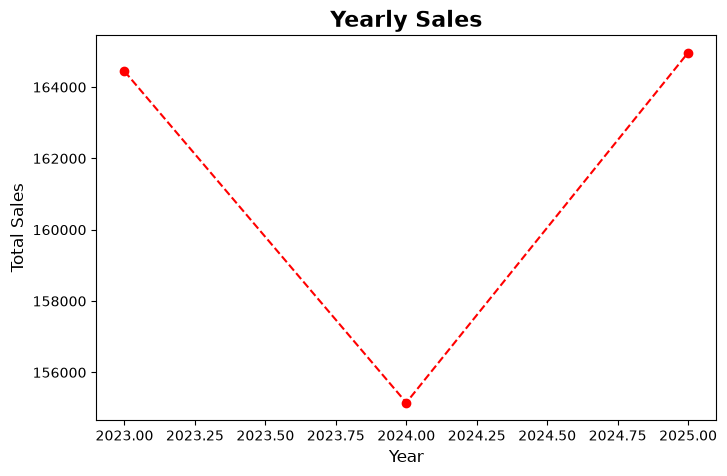

In [82]:
plt.figure(figsize=(8, 5))

plt.plot(
    yearly_sales.index,
    yearly_sales.values,
    ls='dashed',
    color='red',
    marker="o"
)

plt.title("Yearly Sales", fontsize=16, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)


plt.savefig("year_category_profit.png")

plt.show()

In [83]:
yearly_growth = yearly_sales.pct_change() * 100

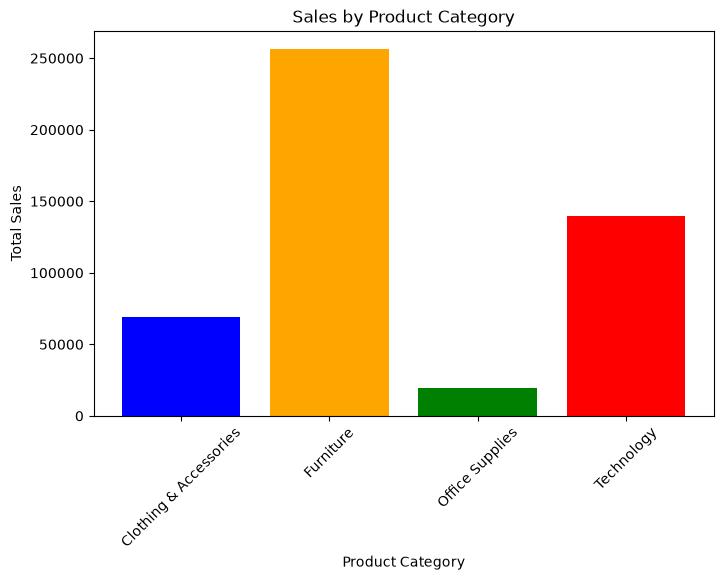

In [84]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_sales.index,
    category_sales.values,
    color = ['blue', 'orange', 'green', 'red', 'purple'],
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.savefig("category_sales.png")
plt.show()

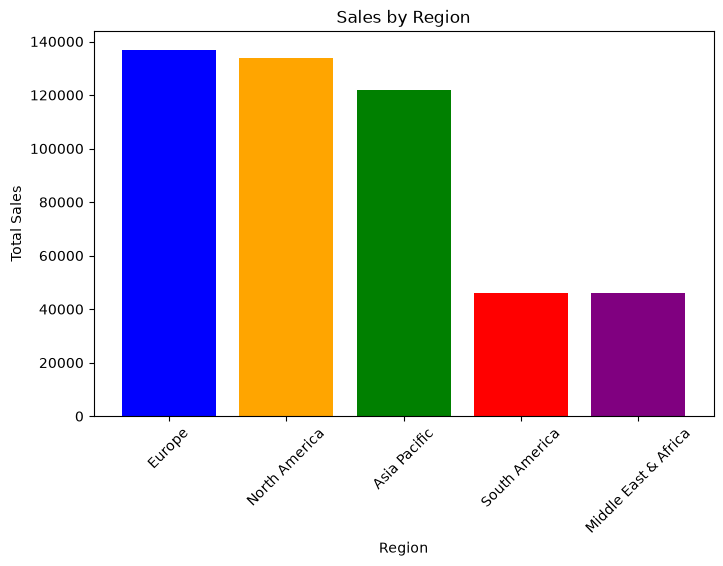

In [85]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_sales.index,
    region_sales.values,
    color = ['blue', 'orange', 'green', 'red', 'purple']
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.savefig("region_sales.png")
plt.show()

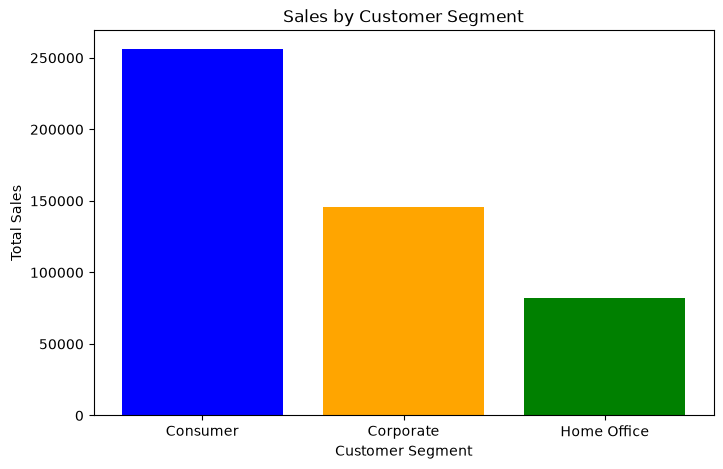

In [86]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_sales.index,
    segment_sales.values,
    color = ['blue', 'orange', 'green', 'red', 'purple']
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.savefig("segment_sales.png")
plt.show()

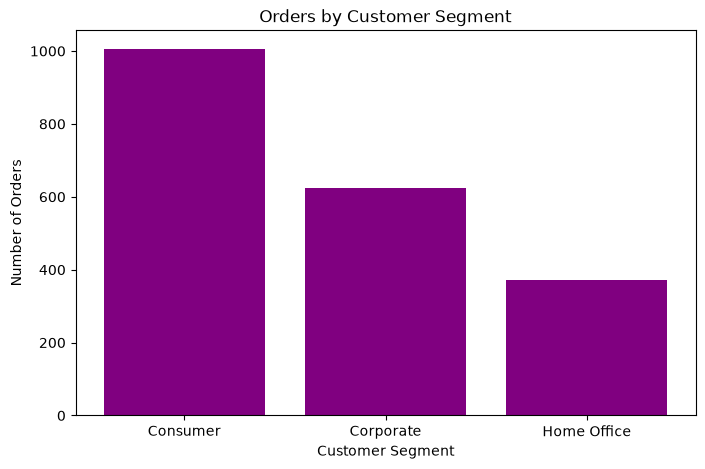

In [87]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_orders.index,
    segment_orders.values,
    color = 'purple'
)

plt.title("Orders by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Orders")

plt.savefig("segment_orders.png")
plt.show()

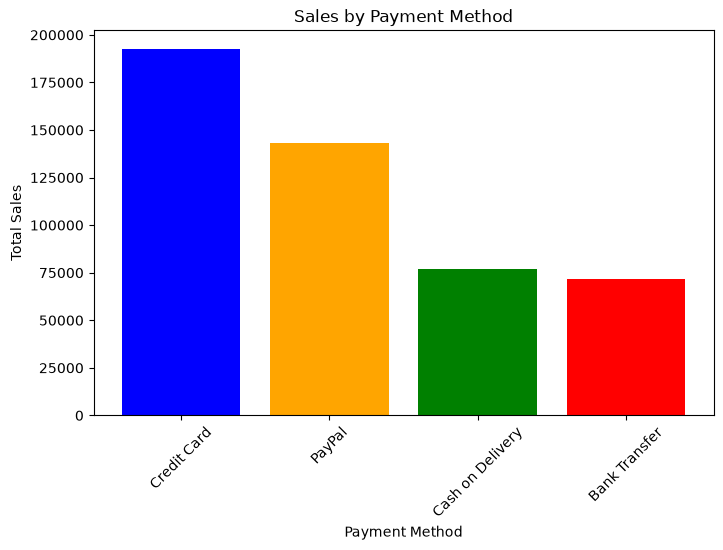

In [88]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_sales.index,
    payment_sales.values,
    color = ['blue', 'orange', 'green', 'red', 'purple']
)

plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.savefig("payment_sales.png")

plt.xticks(rotation=45)

plt.show()

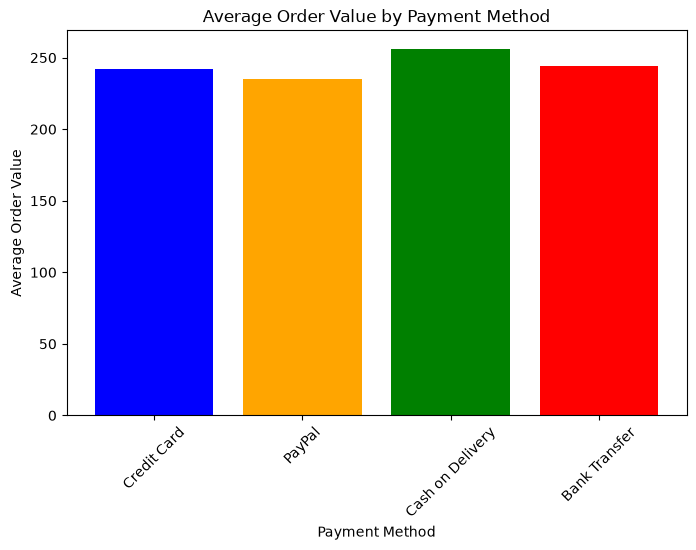

In [89]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_average_order_value.index,
    payment_average_order_value.values,
    color = ['blue', 'orange', 'green', 'red', 'purple']
)

plt.title("Average Order Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Order Value")

plt.xticks(rotation=45)

plt.savefig("payment_average_order_value.png")
plt.show()

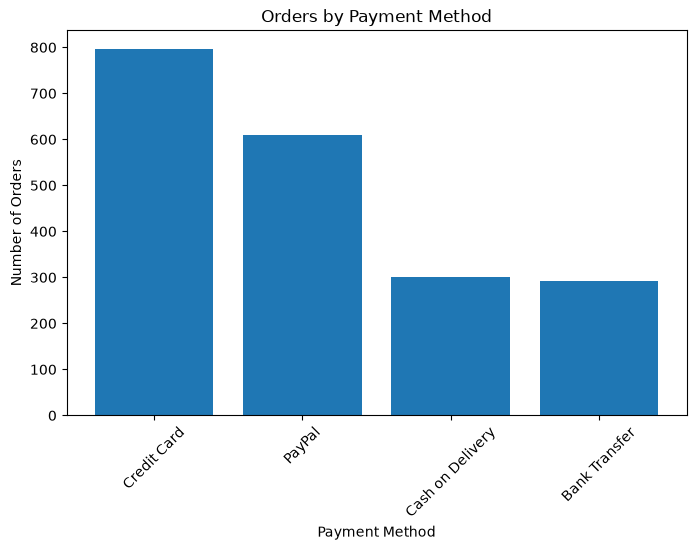

In [90]:
plt.figure(figsize=(8, 5))

plt.bar(
    payment_orders.index,
    payment_orders.values
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.savefig("payment_orders.png")
plt.show()

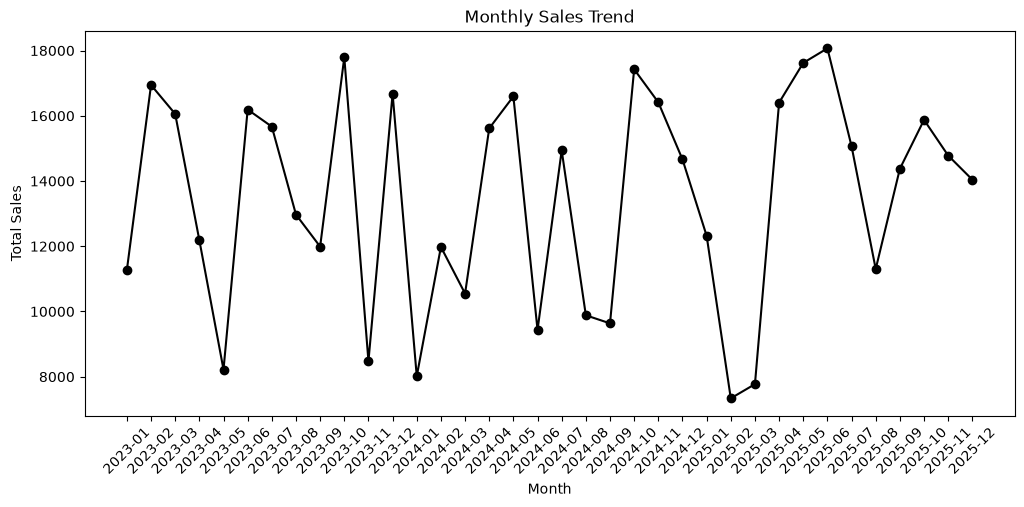

In [91]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    color='black',
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.savefig("monthly_sales_trend.png")
plt.show()

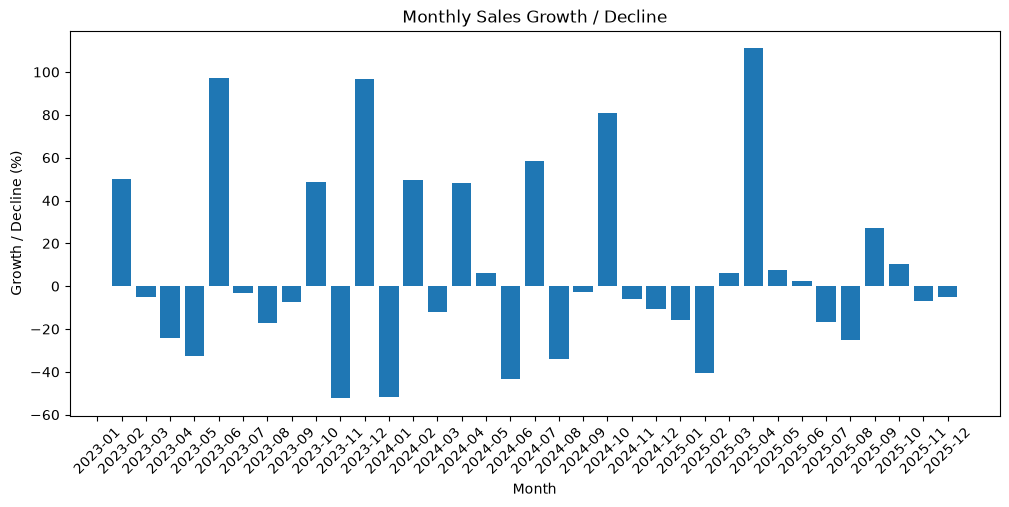

In [92]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_growth.index.astype(str),
    monthly_growth.values
)

plt.title("Monthly Sales Growth / Decline")
plt.xlabel("Month")
plt.ylabel("Growth / Decline (%)")

plt.xticks(rotation=45)

plt.savefig("monthly_growth.png")
plt.show()

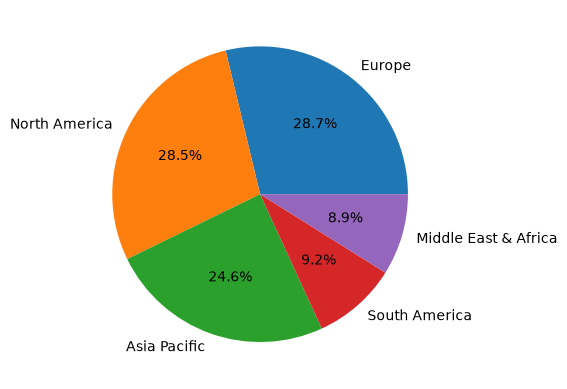

In [93]:
region_profit = (
    df.groupby("Region")["Profit"]
      .sum()
      .sort_values(ascending=False)
)

plt.pie(
    region_profit,labels=region_profit.index, 
    autopct='%1.1f%%'
)

plt.savefig("regional.png")

plt.show()

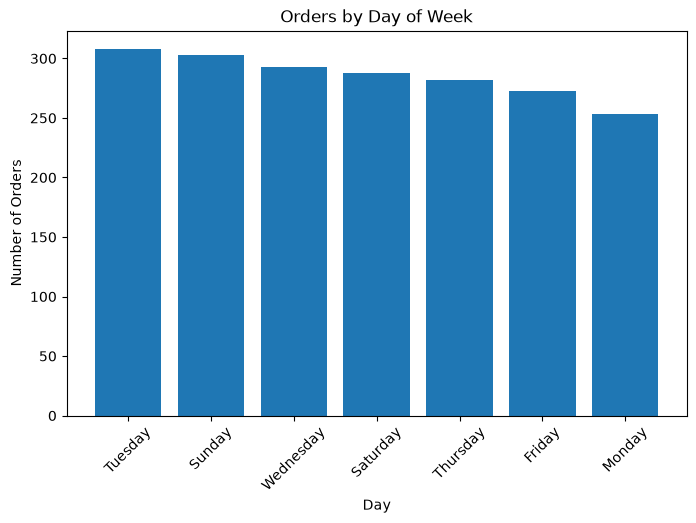

In [94]:
plt.figure(figsize=(8, 5))

plt.bar(
    day_orders.index,
    day_orders.values
)

plt.title("Orders by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.savefig("day_orders.png")
plt.show()

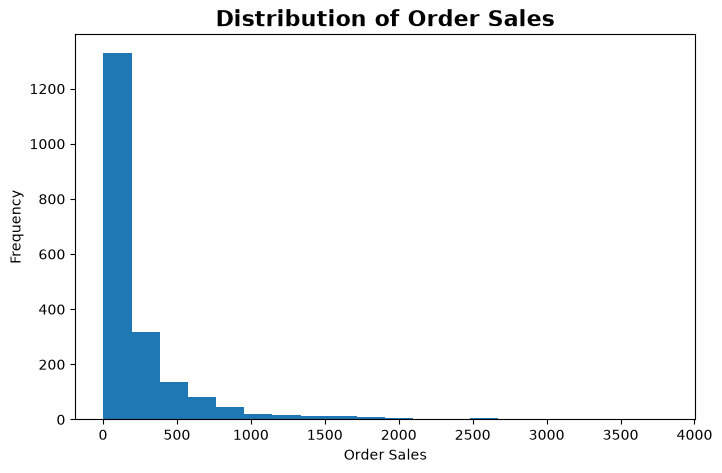

In [95]:
plt.figure(figsize=(8, 5))

plt.hist(
    sales,
    bins=20
)

plt.title("Distribution of Order Sales", fontsize=16, fontweight="bold")
plt.xlabel("Order Sales")
plt.ylabel("Frequency")

plt.savefig("order_sales_distribution.png")
plt.show()

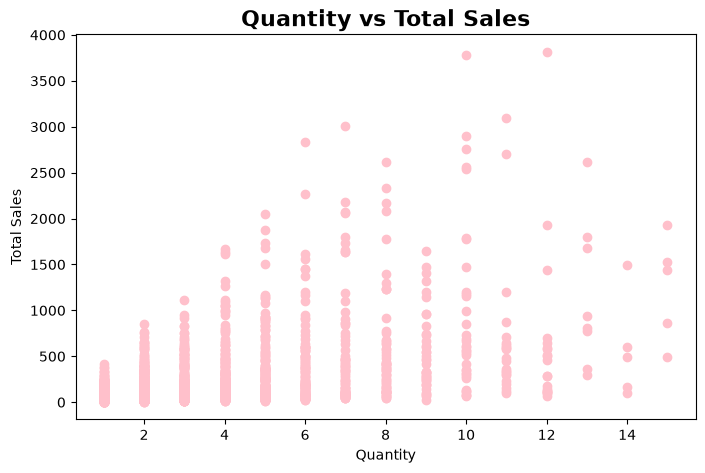

In [96]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Quantity"],
    df["Total_Sales"],
    color = 'pink'
)

plt.title("Quantity vs Total Sales", fontsize=16, fontweight="bold")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.savefig("quantity_vs_total_sales.png")
plt.show()

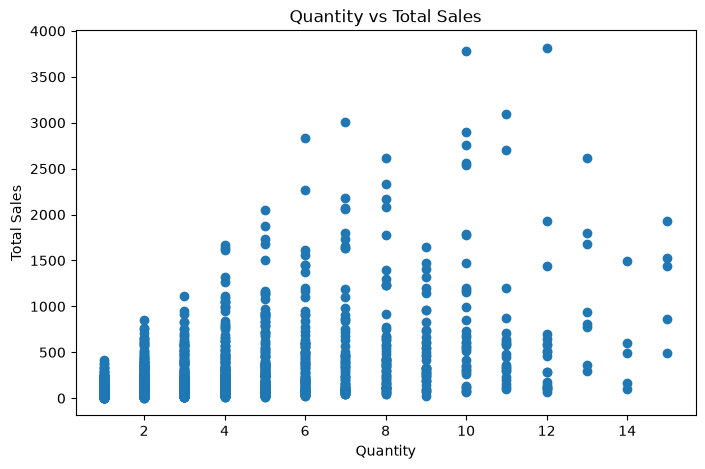

In [97]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Quantity"],
    df["Total_Sales"]
)

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")

plt.savefig("quantity_vs_total_sales.png")
plt.show()